In [134]:
#Data manipulation
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt

# Preprocessing
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
train_test_split,
RandomizedSearchCV,
TimeSeriesSplit,
cross_val_score
)

# K-mean clustering
from sklearn.cluster import KMeans

# Classifier
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn.metrics import (precision_recall_curve,
roc_curve,
RocCurveDisplay,
ConfusionMatrixDisplay
)

from sklearn.metrics import (accuracy_score,
f1_score,
recall_score,
precision_score,
roc_auc_score,
auc
)

from sklearn.metrics import (classification_report,
confusion_matrix
)

# Import tensorflow and keras
import tensorflow
import keras 

# Import pandas-ta
import pandas_ta as ta

In [135]:
files = ["CMA.csv", "HML.csv", "MKT.csv", "RMW.csv", "SMB.csv", "UMD.csv"]
tickers = ["cma", "hml", "mkt", "rmw", "smb", "umd",]

data = pd.DataFrame()

# Load files, extract the 'Close' column, and concatenate DataFrames
for i, file in enumerate(files):
    df = pd.read_csv(file, index_col=0, parse_dates=True, usecols=['date', 'close'])
    df.columns = [f"Close_{tickers[i]}"]  # Rename 'Close' column with ticker suffix
    data = pd.concat([data, df], axis=1)

# Also save each original ticker data into a single dataframe for later calculation of technical indicators
for ticker in tickers:
    globals()[ticker] = pd.read_csv(ticker + ".csv", index_col=0, parse_dates=True)

# Save the concatenated DataFrame to a new CSV file
data.to_csv("concatenated_closes.csv")

data


,Close_cma,Close_hml,Close_mkt,Close_rmw,Close_smb,Close_umd
date,,,,,,
2/1/2014,100.557344,101.654116,94.677887,100.240243,101.235292,98.681401
3/1/2014,100.452750,103.314478,94.177525,99.544800,100.475639,98.564815
6/1/2014,100.386385,102.445666,94.693658,98.665899,98.574632,99.743182
7/1/2014,99.739388,100.809123,97.162546,99.425262,98.126280,100.336994
8/1/2014,100.057959,100.218158,96.824794,99.817369,97.780785,100.198034
...,...,...,...,...,...,...
24/4/2024,163.279450,137.004451,127.042559,105.443845,116.124809,191.263376
25/4/2024,162.954590,136.450907,127.374724,105.673171,116.582596,191.810751
26/4/2024,161.715370,137.514225,126.979863,106.109936,116.859371,191.888061


In [136]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Close_cma,2507.0,121.447539,16.351098,99.142622,107.595953,117.245210,129.907561,166.667970
Close_hml,2507.0,130.463038,17.471080,99.472920,119.446821,131.180002,140.382946,170.913791
Close_mkt,2507.0,131.681843,14.473155,89.455829,120.994125,132.149616,143.955931,155.459147
Close_rmw,2507.0,104.424673,7.689591,84.335946,99.687239,103.522896,108.547883,133.273850
Close_smb,2507.0,108.093572,14.970156,73.234252,95.702319,114.557540,119.913614,130.826035
Close_umd,2507.0,133.747526,23.839062,94.153230,110.983528,138.850625,146.072182,197.827201


In [137]:
# check for missing values
data.isnull().sum()

Close_cma    0
Close_hml    0
Close_mkt    0
Close_rmw    0
Close_smb    0
Close_umd    0
dtype: int64

In [138]:
files = ["CMA.csv", "HML.csv", "MKT.csv", "RMW.csv", "SMB.csv", "UMD.csv"]
tickers = ["cma", "hml", "mkt", "rmw", "smb", "umd"]

ret = pd.DataFrame()

# Load files, extract the 'RET' column, and concatenate DataFrames
for i, file in enumerate(files):
    df = pd.read_csv(file, index_col=0, parse_dates=True, usecols=['date', 'return'])
    df.columns = [f"RET_{tickers[i]}"]  # Rename 'RET' column with ticker suffix
    ret = pd.concat([ret, df], axis=1)

# Save the concatenated DataFrame to a new CSV file if needed
ret.to_csv("concatenated_returns.csv")

ret

,RET_cma,RET_hml,RET_mkt,RET_rmw,RET_smb,RET_umd
date,,,,,,
2/1/2014,0.005573,0.016541,-0.053221,0.002402,0.012353,-0.013186
3/1/2014,-0.001040,0.016333,-0.005285,-0.006938,-0.007504,-0.001181
6/1/2014,-0.000661,-0.008409,0.005480,-0.008829,-0.018920,0.011955
7/1/2014,-0.006445,-0.015975,0.026072,0.007696,-0.004548,0.005953
8/1/2014,0.003194,-0.005862,-0.003476,0.003944,-0.003521,-0.001385
...,...,...,...,...,...,...
24/4/2024,-0.006187,-0.010302,0.003068,0.003958,-0.005578,0.005125
25/4/2024,-0.001990,-0.004040,0.002615,0.002175,0.003942,0.002862
26/4/2024,-0.007605,0.007793,-0.003100,0.004133,0.002374,0.000403


In [139]:
# Define the SMA periods
sma_periods = [5, 10, 20, 50, 100, 200]

# Loop through each ticker and calculate SMA for each period
for ticker in tickers:
    # Identify the column that contains the close prices (assuming the column name is 'close' followed by the ticker)
    close_col = f"Close_{ticker}"
    
    # Check if the column exists in the data DataFrame
    if close_col in data.columns:
        for period in sma_periods:
            # Calculate SMA
            sma_col = f"SMA_{period}_{ticker}"
            sma_series = ta.sma(data[close_col], length=period)
            
            # Add SMA to the DataFrame with appropriate name
            data[sma_col] = sma_series
    else:
        print(f"Column {close_col} does not exist in the DataFrame.")

print(data)

            Close_cma   Close_hml   Close_mkt   Close_rmw   Close_smb  \
date                                                                    
2/1/2014   100.557344  101.654116   94.677887  100.240243  101.235292   
3/1/2014   100.452750  103.314478   94.177525   99.544800  100.475639   
6/1/2014   100.386385  102.445666   94.693658   98.665899   98.574632   
7/1/2014    99.739388  100.809123   97.162546   99.425262   98.126280   
8/1/2014   100.057959  100.218158   96.824794   99.817369   97.780785   
...               ...         ...         ...         ...         ...   
24/4/2024  163.279450  137.004451  127.042559  105.443845  116.124809   
25/4/2024  162.954590  136.450907  127.374724  105.673171  116.582596   
26/4/2024  161.715370  137.514225  126.979863  106.109936  116.859371   
29/4/2024  163.066388  138.917666  127.191510  105.437125  117.486626   
30/4/2024  163.662501  138.063658  127.798171  105.398411  117.506506   

            Close_umd   SMA_5_cma  SMA_10_cma  SMA

In [140]:
# Define the EMA periods
ema_periods = [5, 8, 10, 12, 25, 26, 50, 200]

# Loop through each ticker and calculate EMA for each period
for ticker in tickers:
    # Identify the column that contains the close prices (assuming the column name is 'close' followed by the ticker)
    close_col = f"Close_{ticker}"
    
    # Check if the column exists in the data DataFrame
    if close_col in data.columns:
        for period in ema_periods:
            # Calculate EMA
            ema_col = f"EMA_{period}_{ticker}"
            ema_series = ta.ema(data[close_col], length=period)
            
            # Add EMA to the DataFrame with appropriate name
            data[ema_col] = ema_series
    else:
        print(f"Column {close_col} does not exist in the DataFrame.")

print(data) 

            Close_cma   Close_hml   Close_mkt   Close_rmw   Close_smb  \
date                                                                    
2/1/2014   100.557344  101.654116   94.677887  100.240243  101.235292   
3/1/2014   100.452750  103.314478   94.177525   99.544800  100.475639   
6/1/2014   100.386385  102.445666   94.693658   98.665899   98.574632   
7/1/2014    99.739388  100.809123   97.162546   99.425262   98.126280   
8/1/2014   100.057959  100.218158   96.824794   99.817369   97.780785   
...               ...         ...         ...         ...         ...   
24/4/2024  163.279450  137.004451  127.042559  105.443845  116.124809   
25/4/2024  162.954590  136.450907  127.374724  105.673171  116.582596   
26/4/2024  161.715370  137.514225  126.979863  106.109936  116.859371   
29/4/2024  163.066388  138.917666  127.191510  105.437125  117.486626   
30/4/2024  163.662501  138.063658  127.798171  105.398411  117.506506   

            Close_umd   SMA_5_cma  SMA_10_cma  SMA

In [141]:
# Define the RSI periods
rsi_periods = [5, 9, 14, 30]

# Loop through each ticker and calculate RSI for each period
for ticker in tickers:
    # Identify the column that contains the close prices (assuming the column name is 'close' followed by the ticker)
    close_col = f"Close_{ticker}"
    
    # Check if the column exists in the data DataFrame
    if close_col in data.columns:
        for period in rsi_periods:
            # Calculate RSI
            rsi_col = f"RSI_{period}_{ticker}"
            rsi_series = ta.rsi(data[close_col], length=period)
            
            # Add RSI to the DataFrame with appropriate name
            data[rsi_col] = rsi_series
    else:
        print(f"Column {close_col} does not exist in the DataFrame.")

print(data)

            Close_cma   Close_hml   Close_mkt   Close_rmw   Close_smb  \
date                                                                    
2/1/2014   100.557344  101.654116   94.677887  100.240243  101.235292   
3/1/2014   100.452750  103.314478   94.177525   99.544800  100.475639   
6/1/2014   100.386385  102.445666   94.693658   98.665899   98.574632   
7/1/2014    99.739388  100.809123   97.162546   99.425262   98.126280   
8/1/2014   100.057959  100.218158   96.824794   99.817369   97.780785   
...               ...         ...         ...         ...         ...   
24/4/2024  163.279450  137.004451  127.042559  105.443845  116.124809   
25/4/2024  162.954590  136.450907  127.374724  105.673171  116.582596   
26/4/2024  161.715370  137.514225  126.979863  106.109936  116.859371   
29/4/2024  163.066388  138.917666  127.191510  105.437125  117.486626   
30/4/2024  163.662501  138.063658  127.798171  105.398411  117.506506   

            Close_umd   SMA_5_cma  SMA_10_cma  SMA

C:\Users\tonfo\AppData\Local\Temp\ipykernel_37820\957566562.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[rsi_col] = rsi_series
C:\Users\tonfo\AppData\Local\Temp\ipykernel_37820\957566562.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[rsi_col] = rsi_series
C:\Users\tonfo\AppData\Local\Temp\ipykernel_37820\957566562.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once usi

In [142]:
# Define the Bollinger Bands parameters
bb_params = [
    (10, 1.5),
    (20, 2),
    (50, 2.5)
]

# Loop through each ticker and calculate Bollinger Bands for each parameter set
for ticker in tickers:
    # Identify the column that contains the close prices (assuming the column name is 'close' followed by the ticker)
    close_col = f"Close_{ticker}"
    
    # Check if the column exists in the data DataFrame
    if close_col in data.columns:
        for period, std_dev in bb_params:
            # Calculate Bollinger Bands
            bb = ta.bbands(data[close_col], length=period, std=std_dev)
            
            # Extract the Bollinger Bands components from the returned DataFrame
            bb_upper_col = bb.columns[0]
            bb_middle_col = bb.columns[1]
            bb_lower_col = bb.columns[2]
            
            bb_upper = bb[bb_upper_col]
            bb_middle = bb[bb_middle_col]
            bb_lower = bb[bb_lower_col]
            
            # Add Bollinger Bands components to the DataFrame with appropriate names
            data[f"BB_upper_{period}_{std_dev}_{ticker}"] = bb_upper
            data[f"BB_middle_{period}_{std_dev}_{ticker}"] = bb_middle
            data[f"BB_lower_{period}_{std_dev}_{ticker}"] = bb_lower
    else:
        print(f"Column {close_col} does not exist in the DataFrame.")

print(data)

            Close_cma   Close_hml   Close_mkt   Close_rmw   Close_smb  \
date                                                                    
2/1/2014   100.557344  101.654116   94.677887  100.240243  101.235292   
3/1/2014   100.452750  103.314478   94.177525   99.544800  100.475639   
6/1/2014   100.386385  102.445666   94.693658   98.665899   98.574632   
7/1/2014    99.739388  100.809123   97.162546   99.425262   98.126280   
8/1/2014   100.057959  100.218158   96.824794   99.817369   97.780785   
...               ...         ...         ...         ...         ...   
24/4/2024  163.279450  137.004451  127.042559  105.443845  116.124809   
25/4/2024  162.954590  136.450907  127.374724  105.673171  116.582596   
26/4/2024  161.715370  137.514225  126.979863  106.109936  116.859371   
29/4/2024  163.066388  138.917666  127.191510  105.437125  117.486626   
30/4/2024  163.662501  138.063658  127.798171  105.398411  117.506506   

            Close_umd   SMA_5_cma  SMA_10_cma  SMA

C:\Users\tonfo\AppData\Local\Temp\ipykernel_37820\3031231226.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"BB_upper_{period}_{std_dev}_{ticker}"] = bb_upper
C:\Users\tonfo\AppData\Local\Temp\ipykernel_37820\3031231226.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"BB_middle_{period}_{std_dev}_{ticker}"] = bb_middle
C:\Users\tonfo\AppData\Local\Temp\ipykernel_37820\3031231226.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, whic

In [143]:
# Build the feature matrix
feat = pd.concat([ret, data], axis=1) # Feature matrix

# Save the matrix
feat.to_csv('feat.csv')

In [144]:
df = pd.read_csv('cma_model.csv')

# Define target
df['Target'] = np.where(df['cma 6m'] > np.log(1.05) * df['return 6m'], 1, 0)

# Drop the last row where there is no label
#df = df.iloc[:-1]

# Drop the rows with NaN value
df.dropna(inplace=True)

X = df.drop(['Target', 'date'],axis=1)
y = df['Target']


In [145]:
#check data
X.to_csv('X_cma.csv')
y.to_csv('y_cma.csv')

In [146]:
X_train,X_test = X[0:600],X[779:780]
y_train, y_test= y[0:600],y[779:780]

# Output the training and test data size
print(f"Train and Test Size {len(X_train)}, {len(X_test)}")

Train and Test Size 600, 1


In [147]:
# Use StandardScaler
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), index=X_train.index, columns=X_train.columns)

# Apply the scaler to the test set
X_test_scaled = pd.DataFrame(scaler.transform(X_test), index=X_test.index, columns=X_test.columns)

X_train_scaled.describe()

,RET_cma,RET_hml,RET_mkt,RET_rmw,RET_smb,RET_umd,Close_cma,Close_hml,Close_mkt,Close_rmw,...,BB_middle_10_1.5_umd,BB_lower_10_1.5_umd,BB_upper_20_2_umd,BB_middle_20_2_umd,BB_lower_20_2_umd,BB_upper_50_2.5_umd,BB_middle_50_2.5_umd,BB_lower_50_2.5_umd,cma 6m,return 6m
count,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,...,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,6.000000e+02,600.000000,6.000000e+02
mean,-1.184238e-17,1.184238e-17,1.776357e-17,-5.921189e-18,4.440892e-18,-1.184238e-17,7.105427e-16,7.105427e-16,-3.813246e-15,-8.526513e-16,...,-1.752672e-15,1.610564e-15,1.089499e-15,-1.089499e-15,4.736952e-16,1.373716e-15,-1.278977e-15,1.894781e-15,0.000000,-4.263256e-16
std,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,...,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834e+00,1.000834,1.000834e+00
min,-3.830998e+00,-3.744837e+00,-5.547969e+00,-3.473065e+00,-4.395884e+00,-3.836412e+00,-2.177304e+00,-1.625293e+00,-2.654574e+00,-2.878628e+00,...,-1.838521e+00,-1.864549e+00,-1.704565e+00,-1.738970e+00,-1.940942e+00,-1.656543e+00,-1.756639e+00,-1.953828e+00,-2.540868,-2.563620e+00
25%,-6.098149e-01,-5.885397e-01,-5.193783e-01,-5.994651e-01,-5.445930e-01,-5.965485e-01,-6.314100e-01,-8.051595e-01,-7.149910e-01,-3.171915e-01,...,-8.728640e-01,-7.915375e-01,-9.570379e-01,-8.626999e-01,-7.070790e-01,-9.907602e-01,-7.412434e-01,-5.018771e-01,-0.641517,-5.739801e-01
50%,1.794492e-02,-7.057521e-02,1.966485e-02,1.536491e-02,6.351803e-02,-1.907706e-02,-7.916630e-02,-3.956074e-01,2.252936e-01,3.635151e-01,...,5.613005e-02,9.995006e-02,2.764346e-02,2.540673e-02,8.875158e-02,1.247589e-01,-1.754988e-02,-6.002811e-02,0.102235,3.373486e-01
75%,6.164193e-01,5.804310e-01,5.703754e-01,6.797075e-01,6.217119e-01,6.295926e-01,5.712852e-01,7.344590e-01,7.866125e-01,6.533008e-01,...,8.455905e-01,8.243131e-01,7.598318e-01,8.543460e-01,8.448372e-01,6.571877e-01,7.758824e-01,9.634906e-01,0.720036,7.360921e-01
max,3.416566e+00,4.334948e+00,5.369493e+00,3.996950e+00,4.046302e+00,4.350155e+00,2.535350e+00,2.250323e+00,1.617207e+00,1.503817e+00,...,1.652371e+00,1.629022e+00,1.878123e+00,1.663354e+00,1.596685e+00,1.943805e+00,1.641175e+00,1.768415e+00,2.105398,1.702239e+00


In [148]:
# Store the scaled data in the original variables
X_train = X_train_scaled
X_test = X_test_scaled

In [149]:
# K-mean clustering
inertia = []

K = range(1, 50)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=999)
    kmeans.fit(X_train.T)
    inertia.append(kmeans.inertia_)

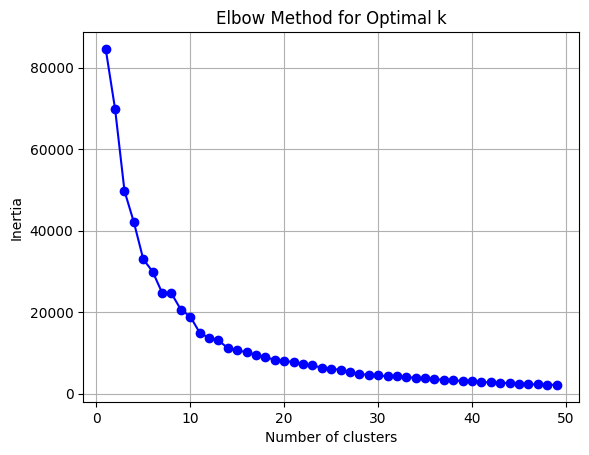

In [150]:
# Elbow plot
plt.plot(K, inertia, 'bo-')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

In [151]:
# Apply K-means with K=13
kmeans = KMeans(n_clusters=13, random_state=999)
kmeans.fit(X_train.T)

KMeans(n_clusters=13, random_state=999)

In [152]:
# Centroids of the clusters
centroids = kmeans.cluster_centers_

# Extract the numerical values from the X_train DataFrame
df = X_train.T
a = df.values

# Find the features that are closest to the centroids
distances = np.linalg.norm(a - centroids[:, np.newaxis], axis=2)
closest_centroid_indices = np.argmin(distances, axis=1)
closest_feat = df.iloc[closest_centroid_indices]

# Display the selected indicators
closest_feat

,199,200,201,202,203,204,205,206,207,208,...,789,790,791,792,793,794,795,796,797,798
EMA_25_mkt,0.567919,0.565543,0.570500,0.580537,0.591947,0.618464,0.639688,0.663978,0.679843,0.697648,...,1.414684,1.429266,1.447173,1.459617,1.476208,1.495301,1.512521,1.531098,1.546703,1.562339
SMA_100_cma,-0.994213,-0.971929,-0.956337,-0.940718,-0.923960,-0.908092,-0.890146,-0.865448,-0.842186,-0.814803,...,2.699485,2.716834,2.732471,2.746696,2.764183,2.788945,2.813581,2.839145,2.859621,2.882528
EMA_26_rmw,-1.924074,-1.949652,-1.968319,-1.993917,-2.020857,-2.058141,-2.089181,-2.112495,-2.138493,-2.158733,...,-0.309989,-0.304661,-0.289563,-0.283446,-0.282566,-0.283820,-0.280250,-0.276567,-0.271600,-0.271798
EMA_25_smb,-0.411982,-0.348326,-0.297678,-0.245338,-0.198204,-0.169977,-0.151070,-0.139364,-0.114414,-0.080401,...,0.657898,0.644488,0.632355,0.629261,0.621242,0.610267,0.592410,0.564217,0.531935,0.503997
EMA_25_umd,-0.074440,-0.051749,-0.026793,0.001088,0.021370,0.032115,0.038514,0.039203,0.038730,0.026990,...,1.113726,1.099755,1.082849,1.058963,1.048096,1.038866,1.022290,1.007350,0.992235,0.979323
EMA_12_cma,0.343546,0.346253,0.322478,0.304298,0.299241,0.258486,0.210894,0.185952,0.137081,0.135838,...,2.037048,2.017845,2.000805,2.016910,2.076240,2.178361,2.243057,2.298825,2.339921,2.385663
RSI_9_cma,1.123193,0.165240,-0.226871,-0.195331,-0.016462,-0.612524,-0.804021,-0.481338,-0.913511,-0.123504,...,-0.646884,-0.517313,-0.542180,0.487297,1.415441,2.027577,1.361349,1.375155,1.174118,1.354439
EMA_26_hml,-0.661402,-0.668716,-0.671682,-0.676230,-0.680419,-0.683783,-0.683141,-0.688034,-0.686710,-0.680065,...,2.269135,2.282866,2.292373,2.303021,2.308973,2.311521,2.319788,2.327621,2.335577,2.345535
RSI_9_rmw,-1.318809,-1.537358,-0.999391,-1.418261,-1.559550,-1.992794,-1.631758,-1.105015,-1.312634,-0.943711,...,0.658183,0.726436,1.360319,0.511786,0.085500,-0.090388,0.294753,0.325020,0.458046,-0.065593
RSI_9_mkt,-0.461562,-0.011327,0.403526,0.682316,0.788410,1.415922,1.140298,1.312138,0.755868,0.900264,...,1.028409,1.080411,1.332607,0.804338,1.123489,1.330265,1.273090,1.429216,1.183434,1.269768


In [153]:
"""# Construct the feature matrices for the training and test sets
df = X_train

columns_to_keep = list(df.columns[:6])  # Create a list from the slice
columns_to_keep.extend(df.columns[-2:])
columns_to_keep.extend(['EMA_26_hml', 'EMA_25_smb',
                      'EMA_26_mkt', 'EMA_25_smb	', 'RSI_9_rmw',
                      'EMA_25_cma', 'RSI_9_cma', 'RSI_9_umd',
                      'RSI_9_rmw', 'RSI_9_smb', 'RSI_9_cma',
                      'SMA_200_smb'])

X_train = X_train[columns_to_keep]
X_test = X_test[columns_to_keep]"""

"# Construct the feature matrices for the training and test sets\ndf = X_train\n\ncolumns_to_keep = list(df.columns[:6])  # Create a list from the slice\ncolumns_to_keep.extend(df.columns[-2:])\ncolumns_to_keep.extend(['EMA_26_hml', 'EMA_25_smb',\n                      'EMA_26_mkt', 'EMA_25_smb\t', 'RSI_9_rmw',\n                      'EMA_25_cma', 'RSI_9_cma', 'RSI_9_umd',\n                      'RSI_9_rmw', 'RSI_9_smb', 'RSI_9_cma',\n                      'SMA_200_smb'])\n\nX_train = X_train[columns_to_keep]\nX_test = X_test[columns_to_keep]"

In [154]:
df = X_train

columns_to_keep = list(df.columns[:6])  # Create a list from the slice
#columns_to_keep.extend(df.columns[-2:])
columns_to_keep.extend(['EMA_25_mkt', 'SMA_100_cma',
                      'EMA_26_rmw', 'EMA_25_smb', 'EMA_25_umd',
                      'EMA_12_cma', 'RSI_9_cma', 'EMA_26_hml',
                      'RSI_9_rmw', 'RSI_9_mkt', 'RSI_9_smb',
                      'RSI_14_hml'])

X_train = X_train[columns_to_keep]
X_test = X_test[columns_to_keep]

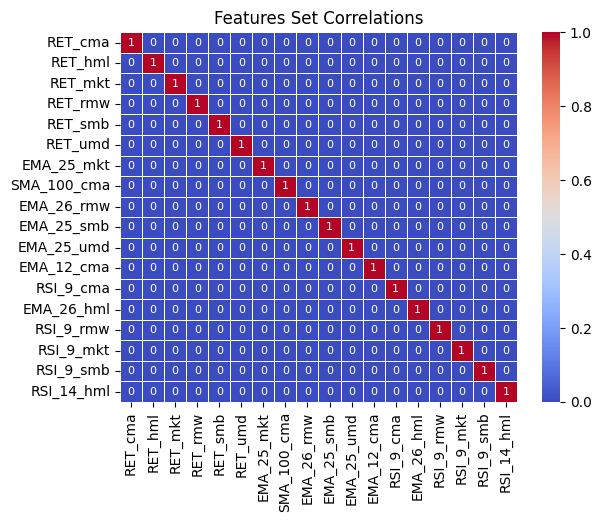

In [155]:
import seaborn as sns
df = X_train

# Show pairs with very high correlation
sns.heatmap(df.corr()>0.8,
annot=True,
annot_kws={"size": 8},
linewidth=.5,
cmap="coolwarm",
cbar=True);

plt.title('Features Set Correlations');

In [156]:
# EDA on the final input matrix
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
RET_cma,600.0,-1.184238e-17,1.000834,-3.830998,-0.609815,0.017945,0.616419,3.416566
RET_hml,600.0,1.184238e-17,1.000834,-3.744837,-0.588540,-0.070575,0.580431,4.334948
RET_mkt,600.0,1.776357e-17,1.000834,-5.547969,-0.519378,0.019665,0.570375,5.369493
RET_rmw,600.0,-5.921189e-18,1.000834,-3.473065,-0.599465,0.015365,0.679707,3.996950
RET_smb,600.0,4.440892e-18,1.000834,-4.395884,-0.544593,0.063518,0.621712,4.046302
RET_umd,600.0,-1.184238e-17,1.000834,-3.836412,-0.596548,-0.019077,0.629593,4.350155
EMA_25_mkt,600.0,1.326346e-15,1.000834,-2.306276,-0.800142,0.361800,0.717259,1.562339
SMA_100_cma,600.0,2.747432e-15,1.000834,-1.792377,-0.542498,-0.040640,0.192985,2.882528
EMA_26_rmw,600.0,6.631732e-16,1.000834,-2.452641,-0.280056,0.401805,0.642191,1.123734
EMA_25_smb,600.0,-1.421085e-16,1.000834,-1.892147,-1.078068,0.294441,0.852150,1.785322


In [157]:
# Create path to save the results
from pathlib import Path

results_path = Path('results', 'lstm_time_series')
if not results_path.exists():
    results_path.mkdir(parents=True)

In [158]:
# Check class frequency
c = np.bincount(y_train)
c

array([141, 459], dtype=int64)

In [159]:
import matplotlib.pyplot as plt
import seaborn as sns  # Import seaborn


In [160]:
# class weight function
def cwts(dfs):
    c0, c1 = np.bincount(dfs)
    w0=(1/c0)*(len(dfs))/2 
    w1=(1/c1)*(len(dfs))/2 
    return {0: w0, 1: w1}

In [161]:
#import src
#from src.config import *
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

# Calculate class weights
class_weight = cwts(y_train)

# Check the class weights
class_weight[0] * c[0], class_weight[1] * c[1]

print(class_weight)

{0: 2.127659574468085, 1: 0.6535947712418301}


In [162]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.metrics import BinaryAccuracy, AUC
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

In [163]:
X_test.to_csv('x_test.csv')
y_test.to_csv('y_test.csv')

In [164]:
y_train.to_csv('y_train.csv')
X_train.to_csv('X_train.csv')

In [165]:
print(f"Length of X_train: {len(X_train)}")
print(f"Length of y_train: {len(y_train)}")
print(f"Length of X_test: {len(X_test)}")
print(f"Length of y_test: {len(y_test)}")


Length of X_train: 600
Length of y_train: 600
Length of X_test: 1
Length of y_test: 1


In [166]:
X_train = pd.read_csv('x_train.csv')
y_train = pd.read_csv('y_train.csv')
X_test = pd.read_csv('x_test.csv')
y_test = pd.read_csv('y_test.csv')

In [167]:
# Remove the 'Unnamed: 0' column if it exists
if 'Unnamed: 0' in X_train.columns:
    X_train = X_train.drop(columns=['Unnamed: 0'])
if 'Unnamed: 0' in y_train.columns:
    y_train = y_train.drop(columns=['Unnamed: 0'])
if 'Unnamed: 0' in X_test.columns:
    X_test = X_test.drop(columns=['Unnamed: 0'])
if 'Unnamed: 0' in y_test.columns:
    y_test = y_test.drop(columns=['Unnamed: 0'])

In [168]:
# Convert to numpy arrays
X_train = X_train.values
y_train = y_train['Target'].values
X_test = X_test.values
y_test = y_test['Target'].values

In [169]:
# Split the training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

In [170]:
# Sequence length for training
seqlen = 10
# Number of features
numfeat = X_train.shape[1]

# Generate sequence input for the training dataset
train_generator = TimeseriesGenerator(X_train, y_train, length=seqlen, batch_size=32)


In [171]:
'''# Sequence length
seqlen = 10
# Number of features
numfeat = X_train.shape[1]

# Generate train and test sequence input
#g = TimeseriesGenerator(X_train, y_train, length=seqlen)
#g_ = TimeseriesGenerator(X_test, y_test, length= 1 )'''

'# Sequence length\nseqlen = 10\n# Number of features\nnumfeat = X_train.shape[1]\n\n# Generate train and test sequence input\n#g = TimeseriesGenerator(X_train, y_train, length=seqlen)\n#g_ = TimeseriesGenerator(X_test, y_test, length= 1 )'

In [172]:
import random
# Set the random seed
def set_seeds(seed=42): 
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seeds

<function __main__.set_seeds(seed=42)>

In [173]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.metrics import BinaryAccuracy, AUC

def create_model(hu=20, lookback=10, features=1):
    
    tf.keras.backend.clear_session()   

    # Instantiate the model
    model = Sequential()
    
    # Add LSTM layer
    model.add(LSTM(units=hu, input_shape=(lookback, features), activation='relu', return_sequences=False, name='LSTM1'))
    # Add Dropout layer
    model.add(Dropout(0.4, name='Dropout1'))
    # Add Dense output layer
    model.add(Dense(units=1, activation='sigmoid', name='Output'))             
    
    # Specify optimizer
    opt = Adam(learning_rate=0.001, epsilon=1e-08, decay=0.0)       
    
    # Model compilation
    model.compile(optimizer=opt, 
                  loss=BinaryCrossentropy(), 
                  metrics=[BinaryAccuracy(name='accuracy', threshold=0.5), AUC()])

    return model


In [174]:
# Create the model
model = create_model(hu=20, lookback=seqlen, features=numfeat)

model.summary()

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ LSTM1 (LSTM)                    │ (None, 20)             │         3,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout1 (Dropout)              │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,141 (12.27 KB)

 Trainable params: 3,141 (12.27 KB)

 Non-trainable params: 0 (0.00 B)

In [175]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [176]:
# Create path to save the results
from pathlib import Path

results_path = Path('results', 'lstm_time_series')
if not results_path.exists():
    results_path.mkdir(parents=True)

In [177]:
model_path = (results_path / 'model.keras').as_posix()

my_callbacks = [
    EarlyStopping(patience=10, monitor='loss', mode='min', verbose=1, restore_best_weights=True),
    ModelCheckpoint(filepath=model_path, verbose=1, monitor='loss', save_best_only=True)
]

In [178]:
print(X_train)

[[-1.36234201 -0.25144808  0.72872395 ... -0.60562713  0.64266241
  -0.08056652]
 [ 1.2880216   0.90004349  0.25485113 ...  0.90026443  0.7907377
   0.14451947]
 [-0.39029057  1.41736013 -0.38516677 ... -0.0047115  -0.06749518
   0.82117782]
 ...
 [ 0.28665465 -0.6022962  -1.61909577 ... -2.17150559 -1.64834935
   0.45852858]
 [-0.27277075 -1.63376452  0.36530874 ...  1.64000875 -1.3146794
  -0.47606007]
 [-0.21784705  1.16062071 -0.12021524 ... -1.35030605 -1.68735522
  -0.26844464]]


In [179]:
print(y_train)

[1 1 1 1 1 0 1 1 1 1 0 1 0 1 1 1 0 1 1 0 0 1 1 1 1 0 1 1 0 0 1 0 1 1 1 0 0
 1 0 0 1 1 0 1 1 1 1 1 1 1 0 1 1 1 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 0 0 1
 1 1 1 1 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 0 1 0
 1 1 1 1 0 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 0 1 1 0 0 1 1 0 1 1 1 1 1 1 1 1 1
 1 1 1 1 0 0 1 1 1 0 0 1 1 1 1 1 1 1 1 1 0 1 1 0 1 0 1 1 1 0 1 1 1 1 1 1 0
 1 1 1 1 1 1 1 1 1 1 0 1 0 1 1 0 1 1 1 1 1 1 1 1 0 1 0 0 1 1 1 0 0 1 1 1 1
 1 1 1 0 0 0 1 1 1 1 1 1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 1 1 1 0 1 1 1 0 1 1 1
 1 0 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1
 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0 1 1 1 0 0 1 1 0 1 0 1 0 1 0 1 1 1 1 0 0 0
 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 1 1 0 1 1 1 1 1
 1 1 0 1 1 0 1 0 0 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 1 0 0 1 0 1 1 0 0 1 0 1 1
 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0 1 0 1 0 1 0 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1 1
 1 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 0 0 0 0 1 1 0]


#### Model Training

In [180]:
# Fit the model
model.fit(train_generator,
          epochs= 152, 
          verbose=1, 
          callbacks=my_callbacks, 
          shuffle=False,
          class_weight=class_weight)

Epoch 1/152


 1/15 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.3438 - auc: 0.3603 - loss: 0.9305
Epoch 1: loss improved from inf to 0.71728, saving model to results/lstm_time_series/model.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4277 - auc: 0.4729 - loss: 0.7398
Epoch 2/152
 1/15 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.4688 - auc: 0.5506 - loss: 0.8364
Epoch 2: loss improved from 0.71728 to 0.69880, saving model to results/lstm_time_series/model.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4829 - auc: 0.5271 - loss: 0.7136 
Epoch 3/152


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


 1/15 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.4688 - auc: 0.4838 - loss: 0.8464
Epoch 3: loss improved from 0.69880 to 0.69497, saving model to results/lstm_time_series/model.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5138 - auc: 0.5496 - loss: 0.7038 
Epoch 4/152
 1/15 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5312 - auc: 0.5425 - loss: 0.8576
Epoch 4: loss improved from 0.69497 to 0.69388, saving model to results/lstm_time_series/model.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5396 - auc: 0.5342 - loss: 0.7121 
Epoch 5/152
 1/15 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.4375 - auc: 0.5040 - loss: 0.8597
Epoch 5: loss did not improve from 0.69388
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5072 - auc: 0.5575 - loss: 0.7052 
Epoch 6/152
 1/15 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.4375 - auc: 0.4818 - loss: 0.8662
Epoch 6: loss improved from 0.69388 to 0.68613, saving model to results/lstm_time_series/model.keras
15

In [181]:
# Manually create a batch for the single test sample
X_test_batch = np.expand_dims(X_test, axis=0)

In [182]:
# Predict on the single test sample
prediction = model.predict(X_test_batch)
print(f'Test Prediction: {prediction[0][0]:.2f}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
Test Prediction: 0.11


#### Model Evaluation


In [183]:
# Evaluate with the training set
y_true = y_train[-(len(X_train)-seqlen):]
y_pred_probs = model.predict(train_generator)  # Predicted probabilities
y_pred = (y_pred_probs > 0.5).astype(int)  # Predicted classes

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [184]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
roc_auc = roc_auc_score(y_true, y_pred_probs)

In [185]:
print(f'Training Accuracy: {accuracy:.2f}')
print(f'Training Precision: {precision:.2f}')
print(f'Training Recall: {recall:.2f}')
print(f'Training F1 Score: {f1:.2f}')
print(f'Training ROC AUC: {roc_auc:.2f}')

Training Accuracy: 0.93
Training Precision: 0.99
Training Recall: 0.92
Training F1 Score: 0.95
Training ROC AUC: 0.99


In [186]:
# Binary classification
y_pred_cm = np.where(y_pred > 0.5, 1, 0)

In [187]:
# Determine confusion matrix
cm = confusion_matrix(y_true, y_pred_cm)

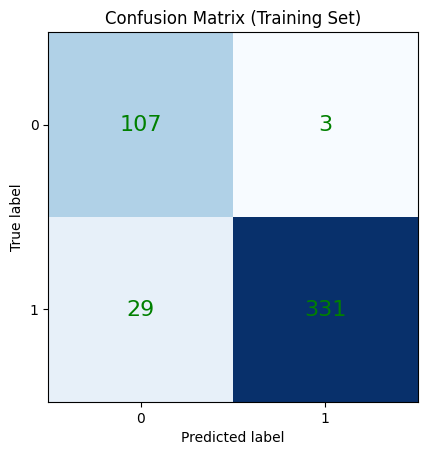

In [188]:
# Plot the confusion matrix
fig, ax = plt.subplots()
ax.imshow(cm, cmap=plt.cm.Blues)
ax.grid(False)

for i in range(cm.shape[0]): # Add number annotations for each cell
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="green", fontsize=16)

# Add labels and title
plt.title('Confusion Matrix (Training Set)')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks(np.arange(2), [0, 1])
plt.yticks(np.arange(2), [0, 1])

plt.show()

In [189]:
'''# Binary classification
y_pred_cm = np.where(y_pred > 0.5, 1, 0)

# Determine confusion matrix
cm = confusion_matrix(y_true, y_pred_cm)

# Plot the confusion matrix
fig, ax = plt.subplots()
ax.imshow(cm, cmap=plt.cm.Blues)
ax.grid(False)

for i in range(cm.shape[0]): # Add number annotations for each cell
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="green", fontsize=16)

# Add labels and title
plt.title('Confusion Matrix (Training Set)')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks(np.arange(2), [0, 1])
plt.yticks(np.arange(2), [0, 1])

plt.show()'''

'# Binary classification\ny_pred_cm = np.where(y_pred > 0.5, 1, 0)\n\n# Determine confusion matrix\ncm = confusion_matrix(y_true, y_pred_cm)\n\n# Plot the confusion matrix\nfig, ax = plt.subplots()\nax.imshow(cm, cmap=plt.cm.Blues)\nax.grid(False)\n\nfor i in range(cm.shape[0]): # Add number annotations for each cell\n    for j in range(cm.shape[1]):\n        ax.text(j, i, cm[i, j], ha="center", va="center", color="green", fontsize=16)\n\n# Add labels and title\nplt.title(\'Confusion Matrix (Training Set)\')\nplt.xlabel(\'Predicted label\')\nplt.ylabel(\'True label\')\nplt.xticks(np.arange(2), [0, 1])\nplt.yticks(np.arange(2), [0, 1])\n\nplt.show()'

In [190]:
# Classification report
print(classification_report(y_true, y_pred_cm))

              precision    recall  f1-score   support

           0       0.79      0.97      0.87       110
           1       0.99      0.92      0.95       360

    accuracy                           0.93       470
   macro avg       0.89      0.95      0.91       470
weighted avg       0.94      0.93      0.93       470



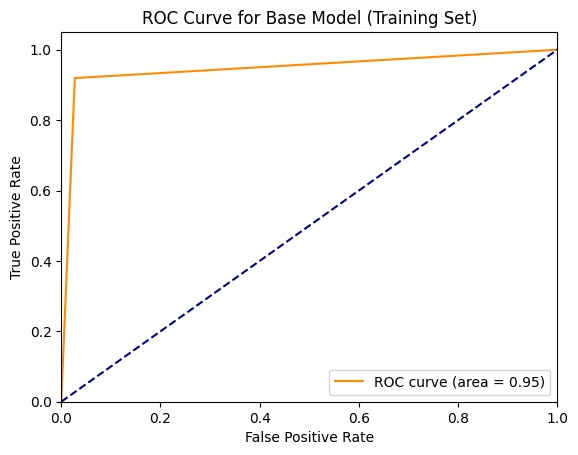

In [191]:
# Determine AUC
fpr, tpr, thresholds = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Base Model (Training Set)')
plt.legend(loc="lower right")
plt.show()

In [192]:
# Manually create a batch for the single test sample
X_test_batch = np.expand_dims(X_test, axis=0)

# Predict on the single test sample
prediction = model.predict(X_test_batch)
print(f'Test Prediction: {prediction[0][0]:.2f}')

# Evaluate with the test set
y_true_test = y_test  # Use the single true value in y_test
y_pred_test_probs = prediction  # Use prediction directly as y_pred_probs

# Binary classification
y_pred_test_cm = (y_pred_test_probs > 0.5).astype(int)

# Determine confusion matrix
cm_test = confusion_matrix(y_true_test, y_pred_test_cm)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Test Prediction: 0.11


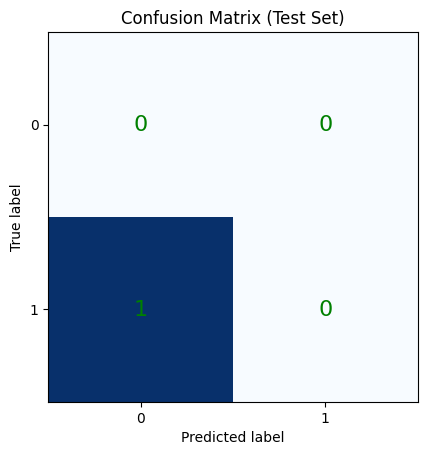

In [193]:
# Evaluate with the test set
y_true_test = y_test  # Use the single true value in y_test
y_pred_test_probs = prediction  # Use prediction directly as y_pred_probs

# Binary classification on test set
y_pred_test_cm = (y_pred_test_probs > 0.5).astype(int)

# Determine confusion matrix for test set
cm_test = confusion_matrix(y_true_test, y_pred_test_cm)

# Plot the confusion matrix for the test set
fig, ax = plt.subplots()
ax.imshow(cm_test, cmap=plt.cm.Blues)
ax.grid(False)

for i in range(cm_test.shape[0]): # Add number annotations for each cell
    for j in range(cm_test.shape[1]):
        ax.text(j, i, cm_test[i, j], ha="center", va="center", color="green", fontsize=16)

# Add labels and title
plt.title('Confusion Matrix (Test Set)')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks(np.arange(2), [0, 1])
plt.yticks(np.arange(2), [0, 1])

plt.show()

In [194]:
# Print classification report for test set
print("Classification Report for Test Set")
print(classification_report(y_true_test, y_pred_test_cm))

Classification Report for Test Set
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       0.0
           1       0.00      0.00      0.00       1.0

    accuracy                           0.00       1.0
   macro avg       0.00      0.00      0.00       1.0
weighted avg       0.00      0.00      0.00       1.0



c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, 